# 03 - Model B: Lightweight CNN (Depthwise Separable)

Build, train, and evaluate **Model B**: a lightweight CNN that replaces Model A's standard convolutions with **depthwise separable convolutions** to cut multiply-accumulate (MAC) operations, under a hard budget of **100,000 trainable parameters** (assignment Task 2).

In [1]:
# --- Environment setup (Google Colab + shared Google Drive, with a local fallback) ---
import os

try:
    from google.colab import drive
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    # Mount the team's shared Drive - 01_data_preparation.ipynb cached the
    # resized/normalized dataset there, and we save checkpoints + results back
    # to it so nobody has to download large files to their own PC.
    drive.mount("/content/drive")
    REPO_DIR = "/content/drive/MyDrive/EN3150-A03-Resource-Constrained-CNN"
else:
    # Not in Colab - use this repo's own local folders instead of Drive.
    REPO_DIR = os.path.abspath("..")

print("IN_COLAB:", IN_COLAB)
print("REPO_DIR:", REPO_DIR)

Mounted at /content/drive
IN_COLAB: True
REPO_DIR: /content/drive/MyDrive/EN3150-A03-Resource-Constrained-CNN


## 1. Config

In [2]:
# --- Config for this notebook (defined here, not in a shared file) ---
CONFIG = {
    "image_size": 64,          # resolution of the cached dataset (<= 64x64 per spec)
    "channels": 3,
    "train_ratio": 0.70,
    "val_ratio": 0.15,
    "test_ratio": 0.15,
    "random_seed": 42,
    "batch_size": 32,
    "epochs": 20,              # assignment requires >= 20 epochs
    "learning_rate": 0.001,    # Adam - same as Model A, so the comparison isolates the architecture
    "dropout_rate": 0.3,
    "dataset_name": "Intel Image Classification",
    "num_classes": 6,
    "class_names": ["buildings", "forest", "glacier", "mountain", "sea", "street"],
    "model_b_max_params": 100000,
}

# --- Paths ---
# Notebook 01 has been run under two different Drive roots, so the cached
# arrays may sit one folder deeper. Look in both and use whichever has them.
PROCESSED_SUBPATH = os.path.join("data", "processed", "intel-image-classification")
CANDIDATE_ROOTS = [REPO_DIR, os.path.join(REPO_DIR, "EN3150-A03-Resource-Constrained-CNN")]

PROCESSED_DIR = os.path.join(REPO_DIR, PROCESSED_SUBPATH)
for root in CANDIDATE_ROOTS:
    if os.path.exists(os.path.join(root, PROCESSED_SUBPATH, "X_train.npy")):
        PROCESSED_DIR = os.path.join(root, PROCESSED_SUBPATH)
        break

# Everything we write goes to REPO_DIR, which is where notebooks 02/05/08 look.
CHECKPOINT_DIR = os.path.join(REPO_DIR, "models", "checkpoints", "model_b")
FINAL_MODEL_DIR = os.path.join(REPO_DIR, "models", "final")
FIGURES_DIR = os.path.join(REPO_DIR, "results", "figures", "model_b")
CONFUSION_DIR = os.path.join(REPO_DIR, "results", "confusion_matrices")
METRICS_DIR = os.path.join(REPO_DIR, "results", "metrics")

for d in (CHECKPOINT_DIR, FINAL_MODEL_DIR, FIGURES_DIR, CONFUSION_DIR, METRICS_DIR):
    os.makedirs(d, exist_ok=True)

print("PROCESSED_DIR:", PROCESSED_DIR)
CONFIG

PROCESSED_DIR: /content/drive/MyDrive/EN3150-A03-Resource-Constrained-CNN/data/processed/intel-image-classification


{'image_size': 64,
 'channels': 3,
 'train_ratio': 0.7,
 'val_ratio': 0.15,
 'test_ratio': 0.15,
 'random_seed': 42,
 'batch_size': 32,
 'epochs': 20,
 'learning_rate': 0.001,
 'dropout_rate': 0.3,
 'dataset_name': 'Intel Image Classification',
 'num_classes': 6,
 'class_names': ['buildings',
  'forest',
  'glacier',
  'mountain',
  'sea',
  'street'],
 'model_b_max_params': 100000}

## 2. Imports

In [3]:
import json
import random
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow import keras
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    precision_score,
    recall_score,
)

print("TensorFlow:", tf.__version__)
print("GPU available:", tf.config.list_physical_devices("GPU"))

TensorFlow: 2.20.0
GPU available: []


## 3. Seed

In [4]:
SEED = CONFIG["random_seed"]
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

## 4. Load Prepared Data

In [5]:
# Load the same 64x64 float32 [0, 1] splits produced by 01_data_preparation.ipynb.
# No re-splitting here: using the cached arrays is what guarantees Model A and
# Model B are trained and evaluated on identical data.
X_train = np.load(os.path.join(PROCESSED_DIR, "X_train.npy"))
y_train = np.load(os.path.join(PROCESSED_DIR, "y_train.npy"))
X_val = np.load(os.path.join(PROCESSED_DIR, "X_val.npy"))
y_val = np.load(os.path.join(PROCESSED_DIR, "y_val.npy"))
X_test = np.load(os.path.join(PROCESSED_DIR, "X_test.npy"))
y_test = np.load(os.path.join(PROCESSED_DIR, "y_test.npy"))

with open(os.path.join(PROCESSED_DIR, "class_names.json")) as f:
    class_names = json.load(f)
assert class_names == CONFIG["class_names"], "class_names.json does not match CONFIG - re-check notebook 01"

print("train/val/test sizes:", len(X_train), len(X_val), len(X_test))
print("image shape:", X_train.shape[1:], "dtype:", X_train.dtype)

train/val/test sizes: 11923 2555 2556
image shape: (64, 64, 3) dtype: float32


## 5. Build Model B

Model B keeps **Model A's skeleton** (same number of stages, same 64 -> 32 -> 16 -> 8 -> 4 resolution schedule, same augmentation) and changes only two things, so the Task 4 comparison isolates the effect of the convolution type:

1. **Standard convolutions become depthwise separable convolutions** (`SeparableConv2D`). A standard 3x3 convolution costs `9 * C_in * C_out` weights. The separable version splits it into one 3x3 depthwise filter per input channel plus a 1x1 pointwise mix, costing `9 * C_in + C_in * C_out`. For the 128 -> 256 stage that is 33,920 weights against 294,912, an 8.7x reduction in that stage alone.
2. **`Flatten -> Dense(256)` becomes `GlobalAveragePooling2D`.** That single dense layer is 1,048,576 parameters in Model A, 73% of the whole model, and no sub-100k budget survives it. Global average pooling collapses each 4x4 feature map to its mean, so the only fully connected layer left is the 6-unit softmax output.

Two deliberate exceptions:

- **The stem stays a standard `Conv2D`.** A depthwise convolution over the 3 RGB input channels would have only 27 weights and could not mix colour information at all. MobileNet uses a full convolution as its stem for the same reason. Ours costs 864 weights, roughly 1% of the budget.
- **One extra separable stage at 8x8** (128 -> 128, no pooling) adds depth without spending resolution, using part of the headroom freed by the two changes above.

Data augmentation (`RandomFlip`, `RandomRotation`, `RandomZoom`) is identical to Model A's, adds **zero** parameters, and applies only during training.

In [6]:
def separable_block(filters, pool=True):
    """SeparableConv2D -> BatchNorm -> ReLU (-> MaxPool).

    `use_bias=False` because BatchNorm's own learned shift (beta) makes the
    convolution bias redundant - the same convention Model A uses.
    """
    layers = [
        keras.layers.SeparableConv2D(filters, kernel_size=3, padding="same", use_bias=False),
        keras.layers.BatchNormalization(),
        keras.layers.Activation("relu"),
    ]
    if pool:
        layers.append(keras.layers.MaxPooling2D(pool_size=2))
    return layers


def build_model_b(input_shape, num_classes):
    """Model B: lightweight CNN built from depthwise separable convolutions."""
    layers = [
        keras.layers.Input(shape=input_shape),
        # Same augmentation as Model A - training-time only, zero parameters.
        keras.layers.RandomFlip("horizontal"),
        keras.layers.RandomRotation(0.05),
        keras.layers.RandomZoom(0.1),
        # Stem: a standard convolution, because a depthwise filter over 3 RGB
        # channels cannot mix colour information.
        keras.layers.Conv2D(32, kernel_size=3, padding="same", use_bias=False),
        keras.layers.BatchNormalization(),
        keras.layers.Activation("relu"),
        keras.layers.MaxPooling2D(pool_size=2),
    ]
    layers += separable_block(64)                  # 32x32 -> 16x16
    layers += separable_block(128)                 # 16x16 -> 8x8
    layers += separable_block(128, pool=False)     # 8x8, extra depth
    layers += separable_block(256)                 # 8x8 -> 4x4
    layers += [
        keras.layers.GlobalAveragePooling2D(),
        keras.layers.Dropout(CONFIG["dropout_rate"]),
        keras.layers.Dense(num_classes, activation="softmax"),
    ]
    return keras.Sequential(layers, name="model_b_lightweight_cnn")


input_shape = (CONFIG["image_size"], CONFIG["image_size"], CONFIG["channels"])
model = build_model_b(input_shape, CONFIG["num_classes"])

## 6. Model Summary

In [7]:
model.summary()

Model: "model_b_lightweight_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ random_flip (RandomFlip)        │ (None, 64, 64, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_rotation                 │ (None, 64, 64, 3)      │             0 │
│ (RandomRotation)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_zoom (RandomZoom)        │ (None, 64, 64, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 64, 64, 32)     │           864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 64, 64, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ separable_conv2d                │ (None, 32, 32, 64)     │         2,336 │
│ (SeparableConv2D)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 32, 32, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ separable_conv2d_1              │ (None, 16, 16, 128)    │         8,768 │
│ (SeparableConv2D)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 16, 16, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ separable_conv2d_2              │ (None, 8, 8, 128)      │        17,536 │
│ (SeparableConv2D)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 8, 8, 128)      │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_3 (Activation)       │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ separable_conv2d_3              │ (None, 8, 8, 256)      │        33,920 │
│ (SeparableConv2D)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 8, 8, 256)      │         1,024 │
│ (BatchNormalization)            │                        │             

 Total params: 67,398 (263.27 KB)

 Trainable params: 66,182 (258.52 KB)

 Non-trainable params: 1,216 (4.75 KB)

## 7. Parameter Count

In [8]:
total_params = model.count_params()
trainable_params = sum(int(np.prod(w.shape)) for w in model.trainable_weights)
non_trainable_params = total_params - trainable_params

print(f"Trainable parameters:      {trainable_params:,}")
print(f"Non-trainable (BN stats):  {non_trainable_params:,}")
print(f"Total parameters:          {total_params:,}")
print(f"Budget (trainable):        {CONFIG['model_b_max_params']:,}")

assert trainable_params <= CONFIG["model_b_max_params"], (
    "Model B exceeds the 100,000 trainable parameter limit!"
)
print(f"Within budget, {CONFIG['model_b_max_params'] - trainable_params:,} parameters to spare.")

Trainable parameters:      66,182
Non-trainable (BN stats):  1,216
Total parameters:          67,398
Budget (trainable):        100,000
Within budget, 33,818 parameters to spare.


**Constraint reminder:** Model B's total *trainable* parameter count must not exceed **100,000**. The assertion above must pass before proceeding to training. BatchNorm's moving mean and variance are counted by `model.count_params()` but are not trained, so both figures are reported.

### Explicit parameter breakdown

Task 2 asks for the network parameters to be detailed explicitly (kernel sizes, filters, fully connected units) and for the trainable total to be *calculated*, not just read off `model.summary()`. The table below derives every layer by hand, and the assertion checks the hand calculation against Keras.

All convolutions use `padding="same"`, stride 1, and `use_bias=False` (BatchNorm's beta replaces the bias):

| Layer type | Trainable parameters |
|---|---|
| `Conv2D(k x k, C_in -> C_out)` | `k * k * C_in * C_out` |
| `SeparableConv2D(k x k, C_in -> C_out)` | `k * k * C_in` (depthwise) `+ C_in * C_out` (pointwise) |
| `BatchNormalization(C)` | `2 * C` trainable (gamma, beta), plus `2 * C` non-trainable (moving mean, variance) |
| `Dense(C_in -> U)` | `C_in * U + U` |

In [9]:
# The architecture written out by hand:
# (name, type, kernel, C_in, C_out, output H=W before pooling, followed by BatchNorm?)
LAYER_SPEC = [
    ("stem_conv",   "conv",  3,   3,  32, 64, True),
    ("sep_block_1", "sep",   3,  32,  64, 32, True),
    ("sep_block_2", "sep",   3,  64, 128, 16, True),
    ("sep_block_3", "sep",   3, 128, 128,  8, True),
    ("sep_block_4", "sep",   3, 128, 256,  8, True),
    ("dense_out",   "dense", 0, 256,   6,  1, False),
]


def layer_params_and_macs(kind, k, c_in, c_out, out_hw, bn):
    """Trainable weights (including the BatchNorm that follows, if any) and
    multiply-accumulate operations for one layer."""
    if kind == "conv":
        weights = k * k * c_in * c_out
        macs = out_hw * out_hw * k * k * c_in * c_out
    elif kind == "sep":
        weights = k * k * c_in + c_in * c_out              # depthwise + pointwise
        macs = out_hw * out_hw * (k * k * c_in + c_in * c_out)
    else:                                                  # dense
        weights = c_in * c_out
        macs = c_in * c_out
    weights += 2 * c_out if bn else c_out                  # BN gamma+beta, or the bias
    return weights, macs


def spec_table(spec):
    rows = []
    for name, kind, k, c_in, c_out, out_hw, bn in spec:
        params, macs = layer_params_and_macs(kind, k, c_in, c_out, out_hw, bn)
        rows.append({
            "Layer": name,
            "Type": kind,
            "Kernel": f"{k}x{k}" if k else "-",
            "In": c_in,
            "Out": c_out,
            "Output (pre-pool)": f"{out_hw}x{out_hw}x{c_out}" if out_hw > 1 else str(c_out),
            "Trainable params": params,
            "MACs": macs,
        })
    return pd.DataFrame(rows)


param_table = spec_table(LAYER_SPEC)
hand_total = int(param_table["Trainable params"].sum())
total_macs = int(param_table["MACs"].sum())

print(f"Hand-calculated trainable parameters: {hand_total:,}")
print(f"Keras trainable parameters:           {trainable_params:,}")
assert hand_total == trainable_params, "Hand calculation does not match Keras - check LAYER_SPEC"
param_table

Hand-calculated trainable parameters: 66,182
Keras trainable parameters:           66,182


,Layer,Type,Kernel,In,Out,Output (pre-pool),Trainable params,MACs
0,stem_conv,conv,3x3,3,32,64x64x32,928,3538944
1,sep_block_1,sep,3x3,32,64,32x32x64,2464,2392064
2,sep_block_2,sep,3x3,64,128,16x16x128,9024,2244608
3,sep_block_3,sep,3x3,128,128,8x8x128,17792,1122304
4,sep_block_4,sep,3x3,128,256,8x8x256,34432,2170880
5,dense_out,dense,-,256,6,6,1542,1536


## 8. MAC Operations

Task 2 defines Model B's purpose as *drastically reducing multiply-accumulate (MAC) operations*, so we count them explicitly. One MAC is one multiply plus one accumulate. For a convolution producing an `H x W` feature map:

- standard: `H * W * k * k * C_in * C_out`
- depthwise separable: `H * W * (k * k * C_in + C_in * C_out)`

The ratio between them is `1 / C_out + 1 / k^2`, so for 3x3 kernels a separable convolution costs roughly one ninth of a standard one once `C_out` is reasonably large. The whole-model saving is smaller than that, because the stem is a standard convolution and operates at full 64x64 resolution.

The cell below totals Model B's MACs and compares them against Model A's architecture (transcribed from `02_model_A_standard_cnn.ipynb`) as the reference point for the reduction claim.

In [10]:
# Model A's architecture written out the same way, purely as a reference point
# (source: 02_model_A_standard_cnn.ipynb - not re-run here).
MODEL_A_SPEC = [
    ("conv_1",    "conv",  3,    3,  32, 64, True),
    ("conv_2",    "conv",  3,   32,  64, 32, True),
    ("conv_3",    "conv",  3,   64, 128, 16, True),
    ("conv_4",    "conv",  3,  128, 256,  8, True),
    ("dense_1",   "dense", 0, 4096, 256,  1, True),
    ("dense_out", "dense", 0,  256,   6,  1, False),
]

model_a_table = spec_table(MODEL_A_SPEC)
model_a_params = int(model_a_table["Trainable params"].sum())
model_a_macs = int(model_a_table["MACs"].sum())

print(f"Model B:   {trainable_params:>10,} trainable params   {total_macs:>12,} MACs/image")
print(f"Model A:   {model_a_params:>10,} trainable params   {model_a_macs:>12,} MACs/image")
print()
print(f"Model B is {model_a_params / trainable_params:.1f}x smaller and costs "
      f"{model_a_macs / total_macs:.1f}x fewer MACs per image.")

Model B:       66,182 trainable params     11,470,336 MACs/image
Model A:    1,439,526 trainable params     61,212,160 MACs/image

Model B is 21.8x smaller and costs 5.3x fewer MACs per image.


## 9. Activation Function Justification

**ReLU** (`max(0, x)`) in every hidden layer, **softmax** only at the 6-way output.

- ReLU is a single compare-and-clamp. `sigmoid` and `tanh` each need an exponential *per activation*, evaluated at every pixel of every feature map, which is 64 x 64 x 32 = 131,072 activations in the stem alone. On a microcontroller with no hardware floating-point unit an `exp` costs tens to hundreds of cycles against roughly one for a compare, so on the edge hardware this assignment targets the activation choice affects inference latency far more than it does on a GPU.
- ReLU also keeps gradients from vanishing through the five stages, which `sigmoid` and `tanh` saturate away.
- Softmax's exponential is unavoidable but negligible here: it runs once per forward pass over 6 values, not once per feature-map pixel. Many edge deployments drop it at inference entirely and take `argmax` of the logits, since softmax is monotonic.
- **ReLU6** (`min(max(0, x), 6)`) is MobileNet's variant, chosen because a bounded activation range survives 8-bit quantization better. We keep plain ReLU because we report float32 results; ReLU6 would be the change to make if Model B were quantized to int8 for actual deployment.
- **BatchNorm** costs nothing at inference. It reduces to a fixed per-channel affine transform using stored running statistics, which inference runtimes fold directly into the preceding convolution's weights.

## 10. Training (>= 20 epochs)

In [11]:
ckpt_path = os.path.join(CHECKPOINT_DIR, "best.keras")

checkpoint_cb = keras.callbacks.ModelCheckpoint(
    ckpt_path, monitor="val_loss", save_best_only=True, verbose=1,
)


class EpochTimer(keras.callbacks.Callback):
    """Record wall-clock seconds per epoch, for the Task 4 comparison table."""

    def on_train_begin(self, logs=None):
        self.times = []

    def on_epoch_begin(self, epoch, logs=None):
        self.epoch_start = time.time()

    def on_epoch_end(self, epoch, logs=None):
        self.times.append(time.time() - self.epoch_start)


timer_cb = EpochTimer()

model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=CONFIG["learning_rate"]),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)

t0 = time.time()
history = model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    batch_size=CONFIG["batch_size"],
    epochs=CONFIG["epochs"],
    shuffle=True,
    callbacks=[checkpoint_cb, timer_cb],
)
total_time = time.time() - t0
avg_time_per_epoch = total_time / CONFIG["epochs"]
print(f"Training ({CONFIG['epochs']} epochs) took {total_time:.1f}s ({avg_time_per_epoch:.1f}s/epoch)")

# Reload the best checkpoint (lowest val_loss, not necessarily the last epoch) before evaluating.
model = keras.models.load_model(ckpt_path)

Epoch 1/20
373/373 ━━━━━━━━━━━━━━━━━━━━ 0s 331ms/step - accuracy: 0.5382 - loss: 1.1858
Epoch 1: val_loss improved from None to 1.69798, saving model to /content/drive/MyDrive/EN3150-A03-Resource-Constrained-CNN/models/checkpoints/model_b/best.keras

Epoch 1: finished saving model to /content/drive/MyDrive/EN3150-A03-Resource-Constrained-CNN/models/checkpoints/model_b/best.keras
373/373 ━━━━━━━━━━━━━━━━━━━━ 136s 347ms/step - accuracy: 0.6239 - loss: 0.9885 - val_accuracy: 0.3041 - val_loss: 1.6980
Epoch 2/20
373/373 ━━━━━━━━━━━━━━━━━━━━ 0s 331ms/step - accuracy: 0.7163 - loss: 0.7803
Epoch 2: val_loss improved from 1.69798 to 1.61578, saving model to /content/drive/MyDrive/EN3150-A03-Resource-Constrained-CNN/models/checkpoints/model_b/best.keras

Epoch 2: finished saving model to /content/drive/MyDrive/EN3150-A03-Resource-Constrained-CNN/models/checkpoints/model_b/best.keras
373/373 ━━━━━━━━━━━━━━━━━━━━ 134s 359ms/step - accuracy: 0.7268 - loss: 0.7496 - val_accuracy: 0.5362 - val_loss

## 11. Training / Validation Loss Curves

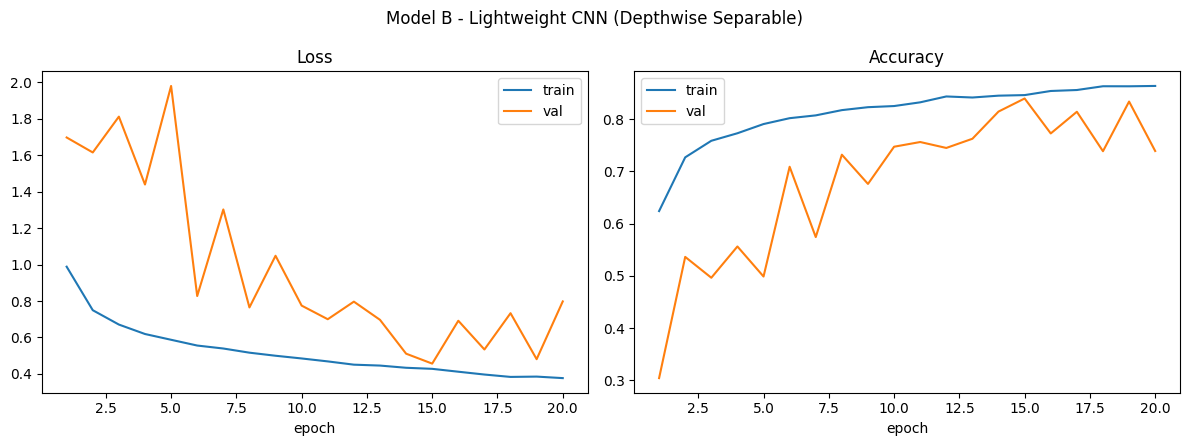

Saved: /content/drive/MyDrive/EN3150-A03-Resource-Constrained-CNN/results/figures/model_b/loss_curve.png


In [12]:
epochs_range = range(1, CONFIG["epochs"] + 1)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

axes[0].plot(epochs_range, history.history["loss"], label="train")
axes[0].plot(epochs_range, history.history["val_loss"], label="val")
axes[0].set_title("Loss")
axes[0].set_xlabel("epoch")
axes[0].legend()

axes[1].plot(epochs_range, history.history["accuracy"], label="train")
axes[1].plot(epochs_range, history.history["val_accuracy"], label="val")
axes[1].set_title("Accuracy")
axes[1].set_xlabel("epoch")
axes[1].legend()

plt.suptitle("Model B - Lightweight CNN (Depthwise Separable)")
plt.tight_layout()
loss_curve_path = os.path.join(FIGURES_DIR, "loss_curve.png")
plt.savefig(loss_curve_path, dpi=150)
plt.show()
print("Saved:", loss_curve_path)

## 12. Test Set Evaluation

In [13]:
y_pred_probs = model.predict(X_test)
y_pred = np.argmax(y_pred_probs, axis=1)

test_accuracy = accuracy_score(y_test, y_pred)
test_precision_macro = precision_score(y_test, y_pred, average="macro")
test_recall_macro = recall_score(y_test, y_pred, average="macro")
cm = confusion_matrix(y_test, y_pred)

print(f"Test accuracy:           {test_accuracy:.4f}")
print(f"Test precision (macro):  {test_precision_macro:.4f}")
print(f"Test recall (macro):     {test_recall_macro:.4f}")
print()
print(classification_report(y_test, y_pred, target_names=class_names))

80/80 ━━━━━━━━━━━━━━━━━━━━ 4s 54ms/step
Test accuracy:           0.8318
Test precision (macro):  0.8388
Test recall (macro):     0.8338

              precision    recall  f1-score   support

   buildings       0.75      0.90      0.82       394
      forest       0.98      0.90      0.94       412
     glacier       0.84      0.73      0.78       444
    mountain       0.76      0.84      0.80       456
         sea       0.83      0.85      0.84       417
      street       0.86      0.78      0.82       433

    accuracy                           0.83      2556
   macro avg       0.84      0.83      0.83      2556
weighted avg       0.84      0.83      0.83      2556



## 13. Confusion Matrix

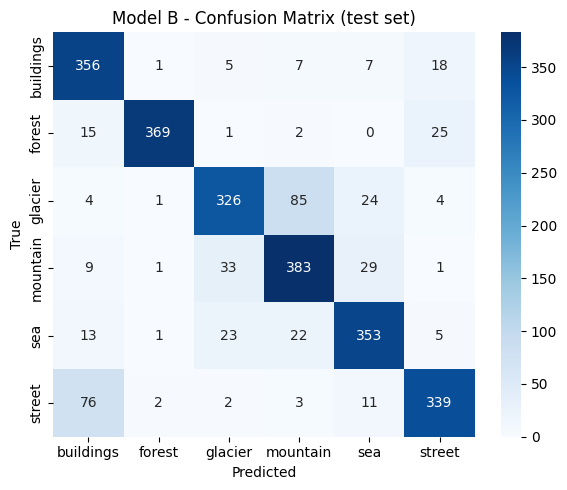

Saved: /content/drive/MyDrive/EN3150-A03-Resource-Constrained-CNN/results/confusion_matrices/model_b.png


In [14]:
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=class_names, yticklabels=class_names)
plt.xlabel("Predicted")
plt.ylabel("True")
plt.title("Model B - Confusion Matrix (test set)")
plt.tight_layout()
cm_path = os.path.join(CONFUSION_DIR, "model_b.png")
plt.savefig(cm_path, dpi=150)
plt.show()
print("Saved:", cm_path)

## 14. Model Size & Training Time

In [15]:
final_model_path = os.path.join(FINAL_MODEL_DIR, "model_b.keras")
model.save(final_model_path)

model_size_kb = os.path.getsize(final_model_path) / 1024

# The .keras archive also carries Adam's optimizer state (two moment estimates
# per trainable parameter), so it is roughly 3x the size of what would actually
# be deployed. Report the raw float32 weight footprint as well - that is the
# number that matters for the edge memory-budget discussion in notebook 08.
weights_size_kb = total_params * 4 / 1024

print(f"Saved final model to: {final_model_path}")
print(f"Model size on disk (.keras archive): {model_size_kb:.1f} KB")
print(f"Weights only, float32:               {weights_size_kb:.1f} KB")
print(f"Average training time per epoch:     {avg_time_per_epoch:.1f}s "
      f"(min {min(timer_cb.times):.1f}s, max {max(timer_cb.times):.1f}s)")

Saved final model to: /content/drive/MyDrive/EN3150-A03-Resource-Constrained-CNN/models/final/model_b.keras
Model size on disk (.keras archive): 879.9 KB
Weights only, float32:               263.3 KB
Average training time per epoch:     133.5s (min 121.9s, max 145.1s)


## 15. Save Results

In [16]:
metrics = {
    "model_name": "Model B (Lightweight CNN)",
    "dataset_name": CONFIG["dataset_name"],
    "test_accuracy": float(test_accuracy),
    "test_precision_macro": float(test_precision_macro),
    "test_recall_macro": float(test_recall_macro),
    "confusion_matrix": cm.tolist(),
    "class_names": class_names,
    "total_params": int(total_params),
    "trainable_params": int(trainable_params),
    "macs": int(total_macs),
    "model_size_kb": float(model_size_kb),
    "weights_size_kb": float(weights_size_kb),
    "epochs": CONFIG["epochs"],
    "avg_time_per_epoch_sec": float(avg_time_per_epoch),
    "time_per_epoch_sec": [float(t) for t in timer_cb.times],
    "history": {k: [float(v) for v in vals] for k, vals in history.history.items()},
}

metrics_path = os.path.join(METRICS_DIR, "model_b.json")
with open(metrics_path, "w") as f:
    json.dump(metrics, f, indent=2)

print("Saved metrics to:", metrics_path)

Saved metrics to: /content/drive/MyDrive/EN3150-A03-Resource-Constrained-CNN/results/metrics/model_b.json


## 16. Conclusion

In [17]:
print(
    f"Model B (Lightweight CNN, depthwise separable, "
    f"{CONFIG['image_size']}x{CONFIG['image_size']} input):\n"
    f"  Test accuracy:                  {test_accuracy:.4f}\n"
    f"  Test precision/recall (macro):  {test_precision_macro:.4f} / {test_recall_macro:.4f}\n"
    f"  Trainable parameters:           {trainable_params:,} (limit {CONFIG['model_b_max_params']:,})\n"
    f"  MACs per image:                 {total_macs:,}\n"
    f"  Model size on disk:             {model_size_kb:.1f} KB "
    f"({weights_size_kb:.1f} KB weights only)\n"
    f"  Avg. time/epoch:                {avg_time_per_epoch:.1f}s"
)

Model B (Lightweight CNN, depthwise separable, 64x64 input):
  Test accuracy:                  0.8318
  Test precision/recall (macro):  0.8388 / 0.8338
  Trainable parameters:           66,182 (limit 100,000)
  MACs per image:                 11,470,336
  Model size on disk:             879.9 KB (263.3 KB weights only)
  Avg. time/epoch:                133.5s
